In [5]:
from network import NeuralNetwork
from data import load_mnist
import numpy as np
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1) #turn on or off


# Plotting

In [6]:
X_train, y_train, X_test, y_test = load_mnist()

Epoch 1/150 loss = 1.3859, accuracy = 70.10%
Epoch 2/150 loss = 0.4719, accuracy = 87.66%
Epoch 3/150 loss = 0.3329, accuracy = 90.71%
Epoch 4/150 loss = 0.2763, accuracy = 92.14%
Epoch 5/150 loss = 0.2393, accuracy = 93.22%
Epoch 6/150 loss = 0.2092, accuracy = 93.87%
Epoch 7/150 loss = 0.1892, accuracy = 94.54%
Epoch 8/150 loss = 0.1638, accuracy = 95.14%
Epoch 9/150 loss = 0.1645, accuracy = 95.09%
Epoch 10/150 loss = 0.1345, accuracy = 96.03%
Epoch 11/150 loss = 0.1266, accuracy = 96.26%
Epoch 12/150 loss = 0.1114, accuracy = 96.70%
Epoch 13/150 loss = 0.1065, accuracy = 96.85%
Epoch 14/150 loss = 0.1138, accuracy = 96.50%
Epoch 15/150 loss = 0.0932, accuracy = 97.15%
Epoch 16/150 loss = 0.0877, accuracy = 97.19%
Epoch 17/150 loss = 0.0876, accuracy = 97.33%
Epoch 18/150 loss = 0.1261, accuracy = 96.18%
Epoch 19/150 loss = 0.0912, accuracy = 97.29%
Epoch 20/150 loss = 0.0772, accuracy = 97.72%
Epoch 21/150 loss = 0.0834, accuracy = 97.33%
Epoch 22/150 loss = 0.1222, accuracy = 96.4

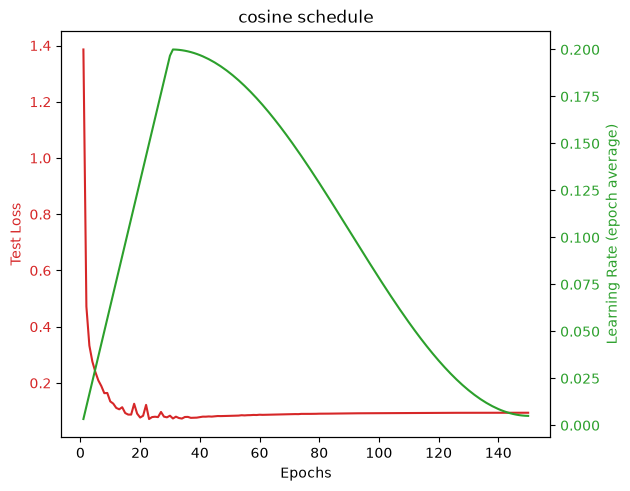

In [65]:
Network = NeuralNetwork([784, 128, 64, 10], weight_init='norm')

epochs = 150
batch_size = 128
steps = int(np.ceil(X_train.shape[1] / batch_size)) * epochs
lr0 = 0.2

step_decay = Network.step_decay(lr0 = lr0, gamma = 0.9, every = 200)
inv_time = Network.inverse_time(lr0 = lr0, lam = 0.9)
cosine = Network.cosine(lr0 = lr0, total = steps, lr_min = 0.005, warmup = 0.2 * steps)
one_cycle = Network.one_cycle(lr_max = lr0, total = steps, pct_up = 0.3, lr_start = None, lr_end = None) 

Network.fit(
    X_train, y_train, 
    epochs=epochs, batch_size=batch_size,
    schedule=cosine, 
    X_val=X_test, y_val=y_test
)

Network.plot_learn(title=f"cosine schedule", plot_loss=True, plot_accuracy=False, plot_learning_rate=True)

# Finding incorrect predictions

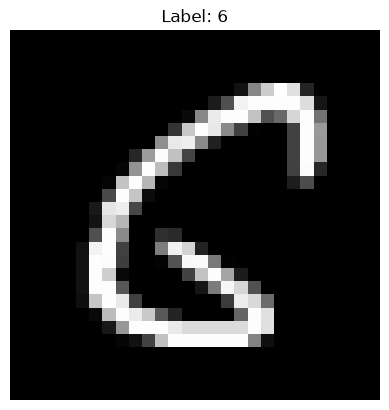

Prediction: 5
confidence = 0.9033483862876892
28


In [74]:

counter = 1
from IPython.display import clear_output, display


while True:
    clear_output(wait=True)

    index = np.random.randint(0, X_test.shape[1])
    image = X_test[:, index].reshape(28, 28)
    prediction = Network.predict(X_test[:, index].reshape(784, 1))[0]

    fig, ax = plt.subplots()
    ax.imshow(image, cmap="gray")
    ax.set_title(f"Label: {y_test[index]}")
    ax.axis("off")
    display(fig)
    plt.close(fig)

    print(f"Prediction: {prediction}")

    if prediction == y_test[index]:
        counter += 1
    else:
        print(f"confidence = {Network.predict_proba(X_test[:, index].reshape(784, 1))[0]}")
        print(counter)
        break

# Little shit here

In [77]:
Network.save("Saved_paramaters/784_128_64_10.npz")